In [1]:

%pip install tensorflow scikit-learn pandas matplotlib seaborn pillow



  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [31]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

IMG_HEIGHT = 32
IMG_WIDTH = 32
CHANNELS = 1
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

def load_image_32(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=1,
        expand_animations=False
    )

    image.set_shape([None, None, 1])

    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.int32)


def create_dataset_32(dataframe, training=False):
    paths = dataframe["image_path"].astype(str).to_numpy()
    labels = dataframe["label_id"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image_32,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds32 = create_dataset_32(train_df, training=True)
val_ds32 = create_dataset_32(val_df)
test_ds32 = create_dataset_32(test_df)

for images, labels in train_ds32.take(1):
    print("Images :", images.shape)
    print("Labels :", labels.shape)
    print("Valeurs des pixels :", 
          float(tf.reduce_min(images)), 
          "à", float(tf.reduce_max(images)))

Images : (64, 32, 32, 1)
Labels : (64,)
Valeurs des pixels : 0.2245098054409027 à 1.0


In [32]:
def convolution_layer(
    x,
    filters,
    kernel_size=5,
    activation="tanh",
    name="conv"
):
    return layers.Conv2D(
        filters=filters,
        kernel_size=kernel_size,
        strides=1,
        padding="valid",
        activation=activation,
        name=name
    )(x)


def pooling_layer(
    x,
    pool_size=2,
    strides=2,
    pooling_type="average",
    name="pool"
):
    if pooling_type.lower() == "average":
        return layers.AveragePooling2D(
            pool_size=pool_size,
            strides=strides,
            name=name
        )(x)

    if pooling_type.lower() == "max":
        return layers.MaxPooling2D(
            pool_size=pool_size,
            strides=strides,
            name=name
        )(x)

    raise ValueError("pooling_type doit être 'average' ou 'max'.")


def fully_connected_layer(
    x,
    units,
    activation="tanh",
    name="dense"
):
    return layers.Dense(
        units=units,
        activation=activation,
        name=name
    )(x)


def build_lenet5(
    input_shape=(32, 32, 1),
    num_classes=33,
    filters1=6,
    filters2=16,
    kernel_size=5,
    pool_size=2,
    dense1_units=120,
    dense2_units=84,
    activation="tanh",
    pooling_type="average"
):
    inputs = keras.Input(shape=input_shape, name="input_image")

    # C1 : 6 cartes de 28 x 28
    x = convolution_layer(
        inputs, filters1, kernel_size,
        activation, name="C1_Conv"
    )

    # S2 : 6 cartes de 14 x 14
    x = pooling_layer(
        x, pool_size, pool_size,
        pooling_type, name="S2_Pooling"
    )

    # C3 : 16 cartes de 10 x 10
    x = convolution_layer(
        x, filters2, kernel_size,
        activation, name="C3_Conv"
    )

    # S4 : 16 cartes de 5 x 5
    x = pooling_layer(
        x, pool_size, pool_size,
        pooling_type, name="S4_Pooling"
    )

    x = layers.Flatten(name="Flatten")(x)

    # C5 / couche dense : 120 neurones
    x = fully_connected_layer(
        x, dense1_units,
        activation, name="C5_FC"
    )

    # F6 : 84 neurones
    x = fully_connected_layer(
        x, dense2_units,
        activation, name="F6_FC"
    )

    # Sortie : 33 classes
    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="Output"
    )(x)

    return keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="LeNet5_Tifinagh_32"
    )


num_classes = len(class_names)

model = build_lenet5(
    input_shape=(32, 32, 1),
    num_classes=num_classes
)

model.summary()

Model: "LeNet5_Tifinagh_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C1_Conv (Conv2D)                │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2_Pooling (AveragePooling2D)   │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3_Conv (Conv2D)                │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4_Pooling (AveragePooling2D)   │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5_FC (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6_FC (Dense)                   │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 33)             │         2,805 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,661 (248.68 KB)

 Trainable params: 63,661 (248.68 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
optimizers_config = {
    "SGD": lambda: keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),
    "Adam": lambda: keras.optimizers.Adam(
        learning_rate=0.001
    ),
    "RMSprop": lambda: keras.optimizers.RMSprop(
        learning_rate=0.001
    )
}

EPOCHS_COMPARISON = 10

optimizer_models = {}
optimizer_histories = {}
optimizer_results = {}

for optimizer_name, optimizer_factory in optimizers_config.items():

    print("\n" + "=" * 60)
    print("Entraînement avec :", optimizer_name)
    print("=" * 60)

    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    np.random.seed(SEED)

    current_model = build_lenet5(
        input_shape=(32, 32, 1),
        num_classes=num_classes
    )

    current_model.compile(
        optimizer=optimizer_factory(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    current_history = current_model.fit(
        train_ds32,
        validation_data=val_ds32,
        epochs=EPOCHS_COMPARISON,
        verbose=1
    )

    training_time = time.time() - start_time

    test_loss_opt, test_accuracy_opt = current_model.evaluate(
        test_ds32,
        verbose=0
    )

    optimizer_models[optimizer_name] = current_model
    optimizer_histories[optimizer_name] = current_history

    optimizer_results[optimizer_name] = {
        "Test Loss": float(test_loss_opt),
        "Test Accuracy": float(test_accuracy_opt),
        "Test Accuracy (%)": float(test_accuracy_opt * 100),
        "Training Time (s)": float(training_time),
        "Epochs": int(len(current_history.history["loss"]))
    }

    print(
        f"{optimizer_name} — "
        f"Test accuracy : {test_accuracy_opt * 100:.2f}%"
    )
    print(f"Temps : {training_time:.2f} secondes")


optimizer_results_df = pd.DataFrame(optimizer_results).T

display(optimizer_results_df.round(4))

optimizer_results_df.to_csv(
    REPORTS_DIR / "comparaison_optimiseurs.csv",
    index=True
)


Entraînement avec : SGD
Epoch 1/10


/home/abd/Documents/TP_CNN_LeNet5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


282/282 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step - accuracy: 0.4132 - loss: 2.3825 - val_accuracy: 0.7817 - val_loss: 0.9949
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 13s 45ms/step - accuracy: 0.8419 - loss: 0.6978 - val_accuracy: 0.8803 - val_loss: 0.5014
Epoch 3/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 17s 59ms/step - accuracy: 0.9008 - loss: 0.4277 - val_accuracy: 0.9081 - val_loss: 0.3859
Epoch 4/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 14s 50ms/step - accuracy: 0.9235 - loss: 0.3205 - val_accuracy: 0.9233 - val_loss: 0.2867
Epoch 5/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/step - accuracy: 0.9391 - loss: 0.2491 - val_accuracy: 0.9402 - val_loss: 0.2328
Epoch 6/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.9528 - loss: 0.1948 - val_accuracy: 0.9510 - val_loss: 0.1888
Epoch 7/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 14s 50ms/step - accuracy: 0.9619 - loss: 0.1605 - val_accuracy: 0.9565 - val_loss: 0.1679
Epoch 8/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 13s 45ms/step - accuracy: 0.9669 - loss: 0.1372 - val_accurac

,Test Loss,Test Accuracy,Test Accuracy (%),Training Time (s),Epochs
SGD,0.1484,0.9588,95.8819,129.2053,10.0
Adam,0.1581,0.9567,95.6747,150.5877,10.0
RMSprop,0.1503,0.9562,95.6229,131.0710,10.0


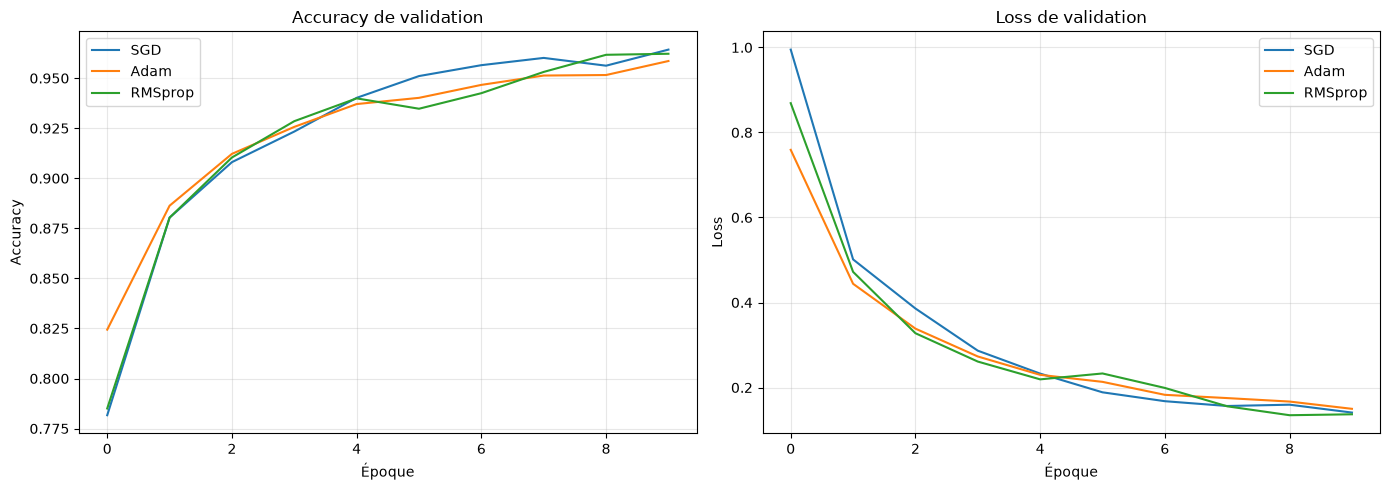

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in optimizer_histories.items():
    axes[0].plot(
        hist.history["val_accuracy"],
        label=name
    )

    axes[1].plot(
        hist.history["val_loss"],
        label=name
    )

axes[0].set_title("Accuracy de validation")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Loss de validation")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "comparaison_optimiseurs.png",
    dpi=150
)
plt.show()

In [35]:
best_optimizer_name = max(
    optimizer_histories,
    key=lambda name: max(
        optimizer_histories[name].history["val_accuracy"]
    )
)

best_model = optimizer_models[best_optimizer_name]

print("Meilleur optimiseur :", best_optimizer_name)
print(
    "Meilleure validation accuracy :",
    f"{max(optimizer_histories[best_optimizer_name].history['val_accuracy']) * 100:.2f}%"
)

best_model_path = MODELS_DIR / "lenet5_tifinagh_32_best.keras"
best_model.save(best_model_path)

print("Modèle sauvegardé :", best_model_path)

Meilleur optimiseur : SGD
Meilleure validation accuracy : 96.43%
Modèle sauvegardé : /home/abd/Documents/TP_CNN_LeNet5/results/models/lenet5_tifinagh_32_best.keras


In [36]:
test_loss, test_accuracy = best_model.evaluate(
    test_ds32,
    verbose=1
)

y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds32
])

y_prob = best_model.predict(
    test_ds32,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

test_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

test_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("Optimiseur :", best_optimizer_name)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"Precision     : {test_precision:.4f}")
print(f"Recall        : {test_recall:.4f}")
print(f"F1-score      : {test_f1:.4f}")

61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9588 - loss: 0.1484
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
Optimiseur : SGD
Test Loss     : 0.1484
Test Accuracy : 95.88%
Precision     : 0.9595
Recall        : 0.9588
F1-score      : 0.9589


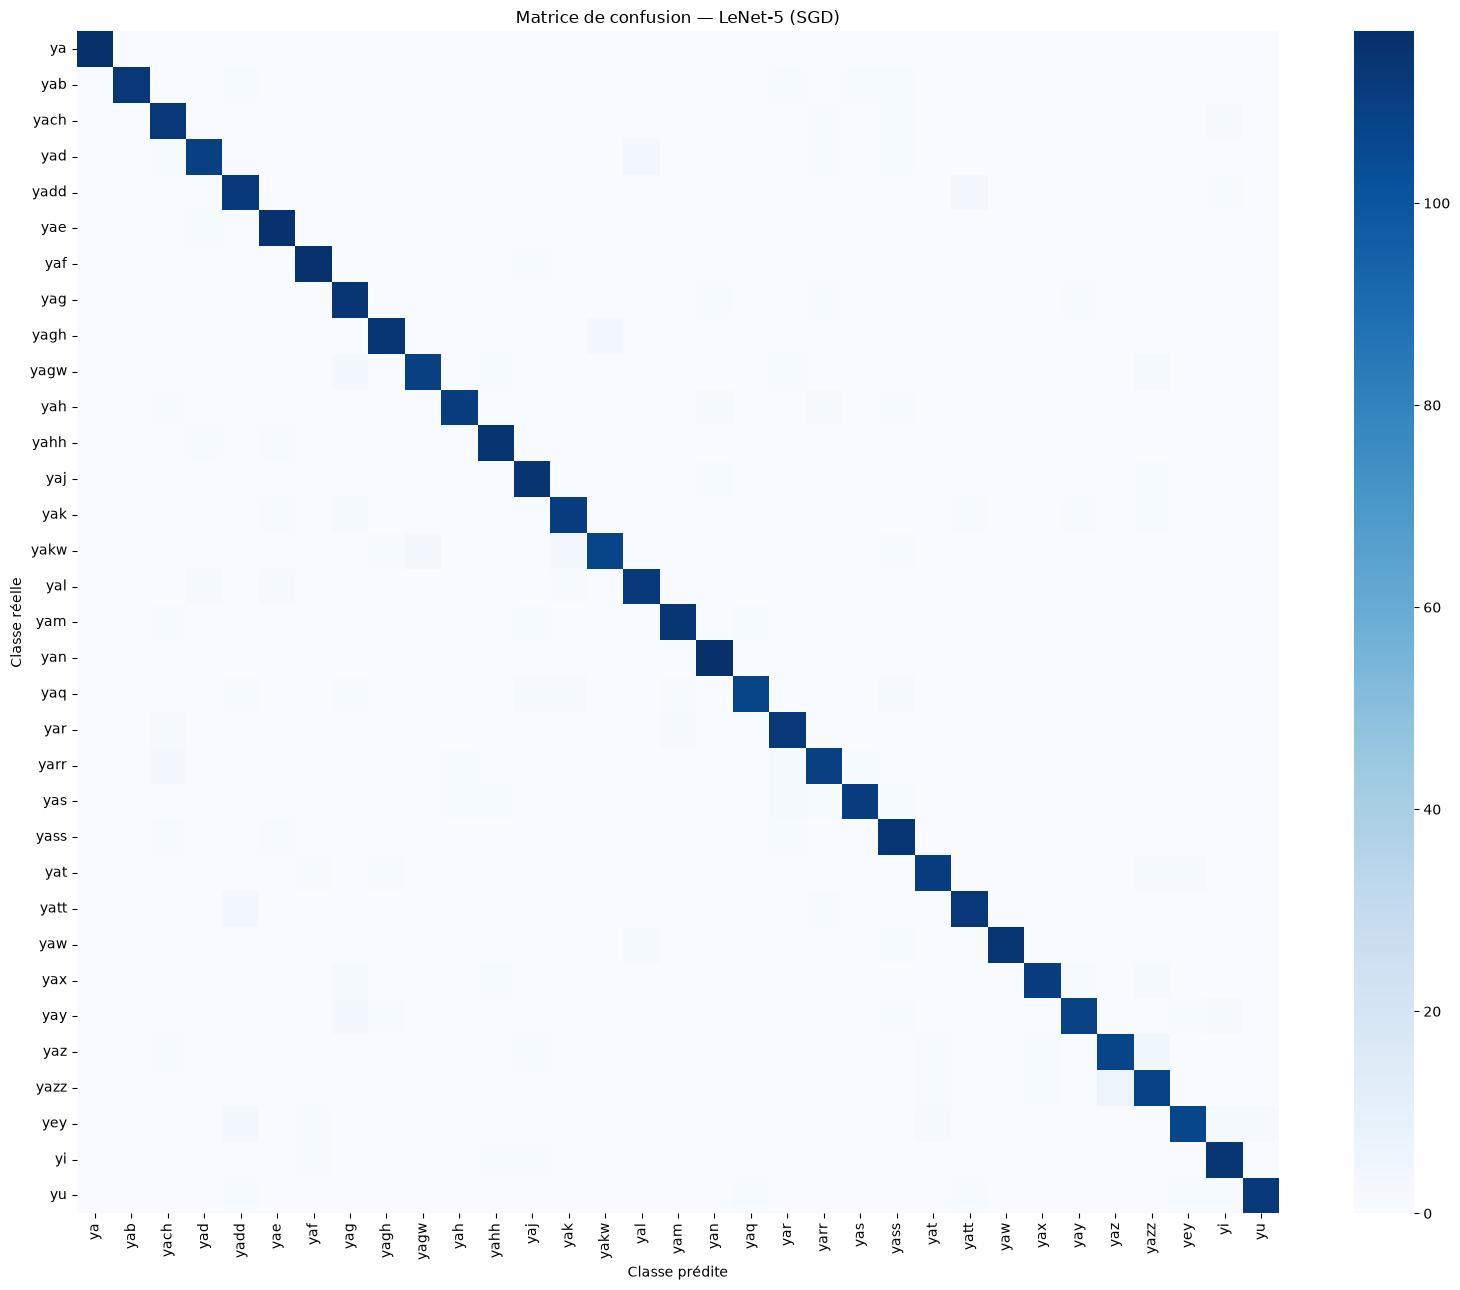

In [37]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(f"Matrice de confusion — LeNet-5 ({best_optimizer_name})")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "matrice_confusion_finale.png",
    dpi=180
)

plt.show()

In [38]:
report_text = classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
)

print(report_text)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    REPORTS_DIR / "rapport_classification_final.csv"
)

display(report_df.round(4))

              precision    recall  f1-score   support

          ya       1.00      1.00      1.00       117
         yab       1.00      0.97      0.98       117
        yach       0.92      0.97      0.94       117
         yad       0.96      0.94      0.95       117
        yadd       0.93      0.96      0.94       117
         yae       0.96      0.99      0.97       117
         yaf       0.97      0.99      0.98       117
         yag       0.91      0.97      0.94       117
        yagh       0.97      0.97      0.97       117
        yagw       0.96      0.94      0.95       117
         yah       0.98      0.95      0.97       117
        yahh       0.97      0.98      0.97       117
         yaj       0.95      0.98      0.97       117
         yak       0.95      0.95      0.95       117
        yakw       0.97      0.92      0.95       117
         yal       0.95      0.96      0.95       117
         yam       0.97      0.97      0.97       117
         yan       0.97    

,precision,recall,f1-score,support
ya,1.0000,1.0000,1.0000,117.0000
yab,1.0000,0.9658,0.9826,117.0000
yach,0.9187,0.9658,0.9417,117.0000
yad,0.9649,0.9402,0.9524,117.0000
yadd,0.9256,0.9573,0.9412,117.0000
yae,0.9587,0.9915,0.9748,117.0000
yaf,0.9748,0.9915,0.9831,117.0000
yag,0.9120,0.9744,0.9421,117.0000
yagh,0.9744,0.9744,0.9744,117.0000
yagw,0.9649,0.9402,0.9524,117.0000


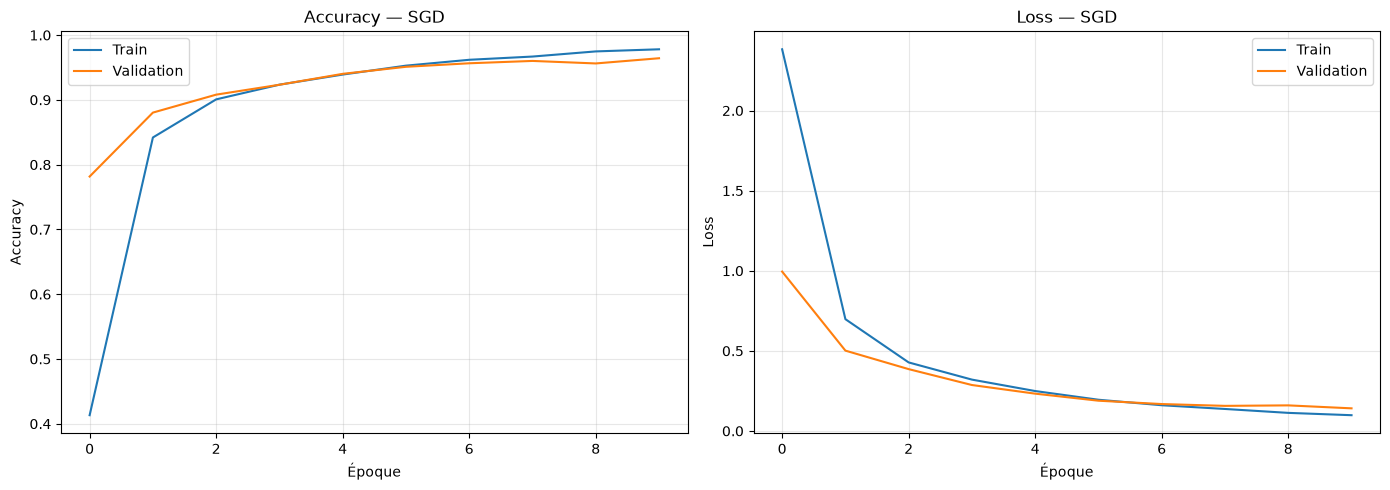

In [39]:
best_history = optimizer_histories[best_optimizer_name].history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(best_history["accuracy"], label="Train")
axes[0].plot(best_history["val_accuracy"], label="Validation")
axes[0].set_title(f"Accuracy — {best_optimizer_name}")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(best_history["loss"], label="Train")
axes[1].plot(best_history["val_loss"], label="Validation")
axes[1].set_title(f"Loss — {best_optimizer_name}")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "courbes_finales.png",
    dpi=150
)

plt.show()

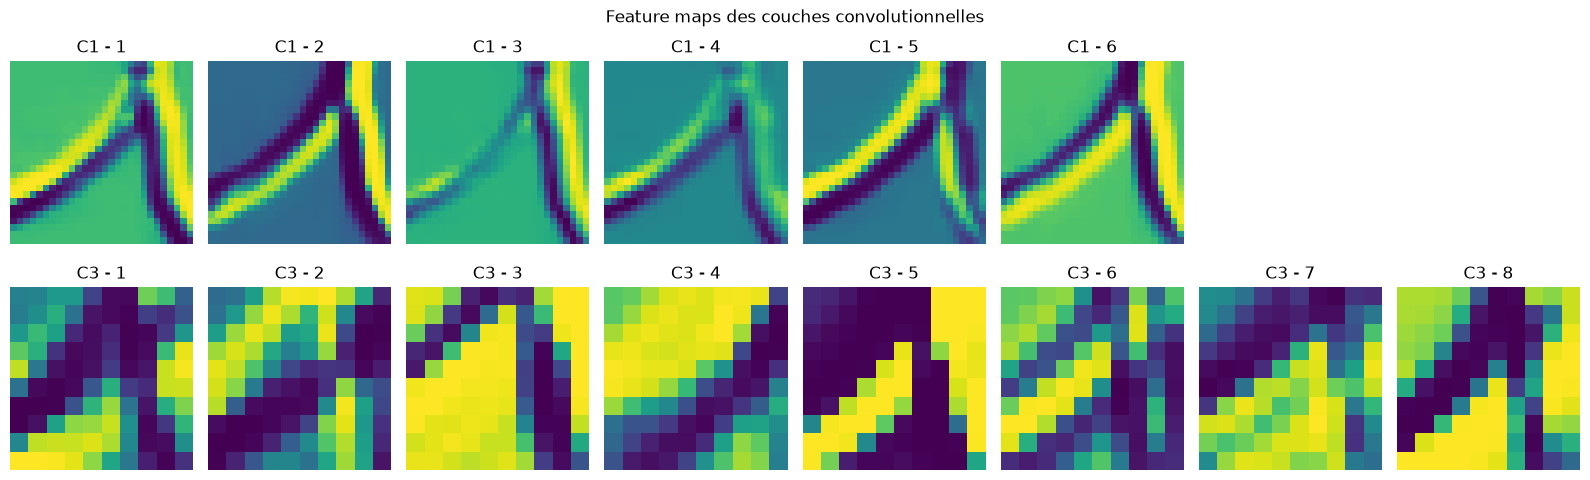

In [40]:
sample_path = test_df.iloc[0]["image_path"]

sample_image = Image.open(sample_path).convert("L")
sample_image = sample_image.resize((32, 32))

sample_array = np.asarray(
    sample_image,
    dtype=np.float32
) / 255.0

sample_array = sample_array[np.newaxis, ..., np.newaxis]

feature_model = keras.Model(
    inputs=best_model.input,
    outputs=[
        best_model.get_layer("C1_Conv").output,
        best_model.get_layer("C3_Conv").output
    ]
)

conv1_maps, conv3_maps = feature_model.predict(
    sample_array,
    verbose=0
)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(6):
    axes[0, i].imshow(conv1_maps[0, :, :, i], cmap="viridis")
    axes[0, i].set_title(f"C1 - {i + 1}")
    axes[0, i].axis("off")

for i in range(6, 8):
    axes[0, i].axis("off")

for i in range(8):
    axes[1, i].imshow(conv3_maps[0, :, :, i], cmap="viridis")
    axes[1, i].set_title(f"C3 - {i + 1}")
    axes[1, i].axis("off")

plt.suptitle("Feature maps des couches convolutionnelles")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "feature_maps_finales.png",
    dpi=150
)

plt.show()

Prédictions correctes : 3702
Prédictions incorrectes : 159


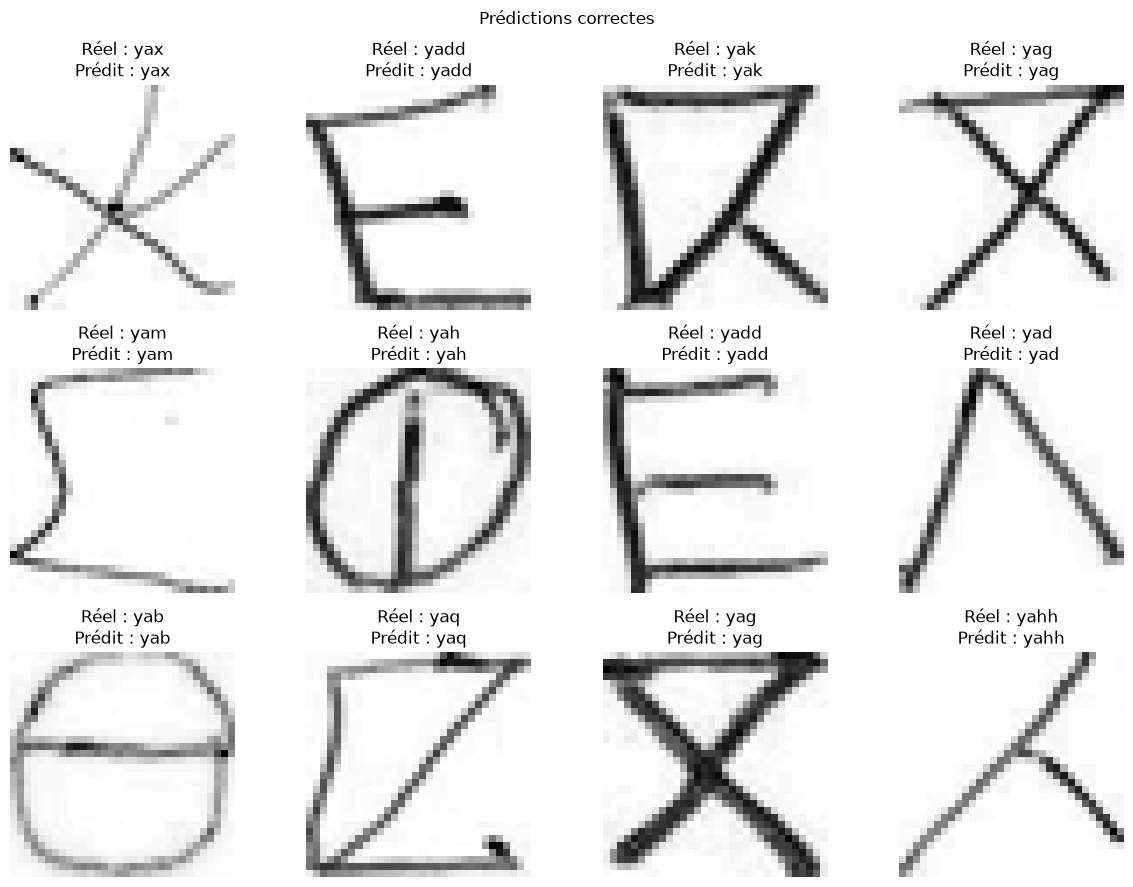

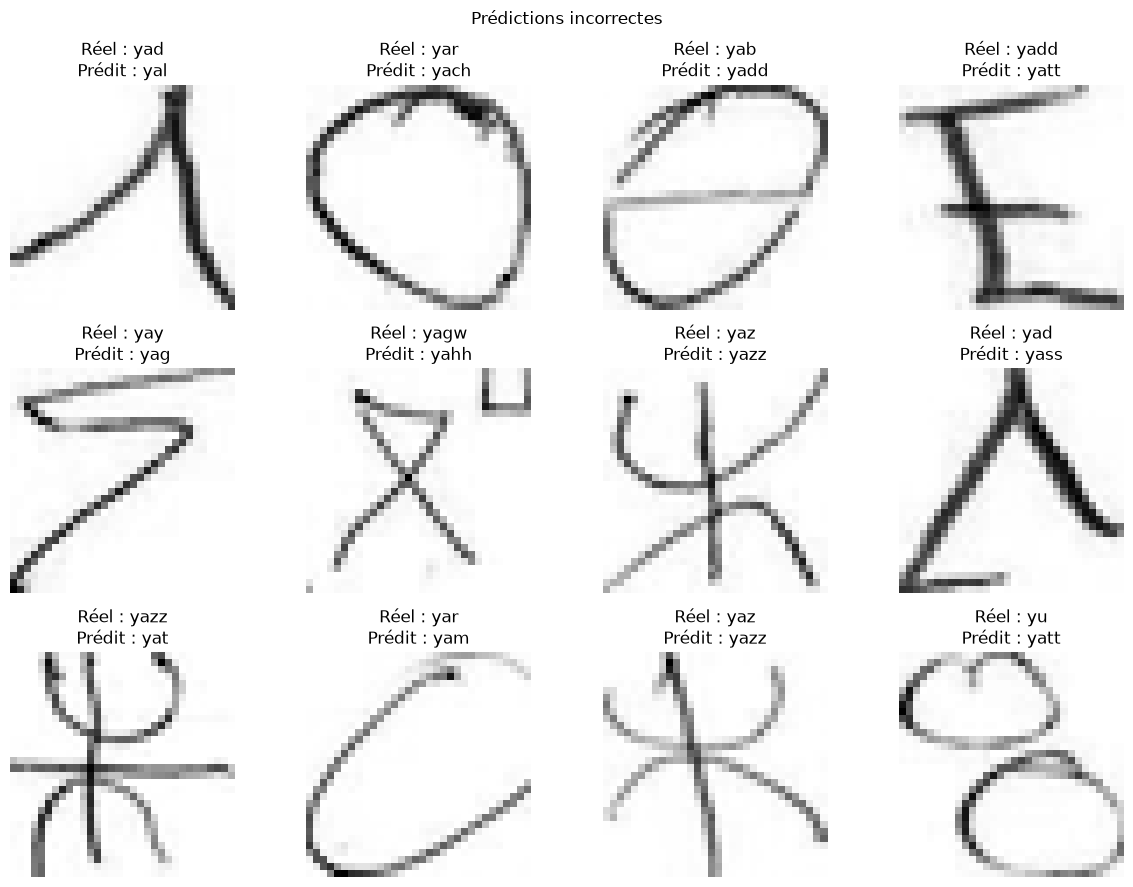

In [41]:
test_paths = test_df["image_path"].to_numpy()

correct_indices = np.where(y_true == y_pred)[0]
incorrect_indices = np.where(y_true != y_pred)[0]

print("Prédictions correctes :", len(correct_indices))
print("Prédictions incorrectes :", len(incorrect_indices))


def display_test_predictions(indices, title, max_images=12):
    if len(indices) == 0:
        print("Aucun exemple :", title)
        return

    selected = indices[:max_images]
    cols = 4
    rows = int(np.ceil(len(selected) / cols))

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(12, 3 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for position, idx in enumerate(selected):
        img = Image.open(test_paths[idx]).convert("L")
        img = img.resize((32, 32))

        true_label = class_names[int(y_true[idx])]
        predicted_label = class_names[int(y_pred[idx])]

        axes[position].imshow(img, cmap="gray")

        axes[position].set_title(
            f"Réel : {true_label}\n"
            f"Prédit : {predicted_label}"
        )

        axes[position].axis("off")

    for j in range(len(selected), len(axes)):
        axes[j].axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


display_test_predictions(
    correct_indices,
    "Prédictions correctes"
)

display_test_predictions(
    incorrect_indices,
    "Prédictions incorrectes"
)

In [43]:
final_results = {
    "Dataset": "AMHCD",
    "Architecture": "LeNet-5 modifiée, entrée 32x32x1",
    "Nombre_images": int(len(df)),
    "Nombre_classes": int(num_classes),
    "Images_train": int(len(train_df)),
    "Images_validation": int(len(val_df)),
    "Images_test": int(len(test_df)),
    "Meilleur_optimiseur": best_optimizer_name,
    "Test_loss": float(test_loss),
    "Test_accuracy": float(test_accuracy),
    "Test_accuracy_percent": float(test_accuracy * 100),
    "Precision_macro": float(test_precision),
    "Recall_macro": float(test_recall),
    "F1_macro": float(test_f1)
}

with open(
    REPORTS_DIR / "resultats_finaux.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        final_results,
        f,
        ensure_ascii=False,
        indent=4
    )

display(pd.DataFrame(
    list(final_results.items()),
    columns=["Paramètre", "Valeur"]
))


,Paramètre,Valeur
0,Dataset,AMHCD
1,Architecture,"LeNet-5 modifiée, entrée 32x32x1"
2,Nombre_images,25740
3,Nombre_classes,33
4,Images_train,18018
5,Images_validation,3861
6,Images_test,3861
7,Meilleur_optimiseur,SGD
8,Test_loss,0.148447
9,Test_accuracy,0.958819
